<a href="https://colab.research.google.com/github/fhs8426004/i2wi-learning-fhs8426004/blob/main/unit15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import glob, importlib, os, subprocess, sys, zipfile

# Colab には pydicom が既定では入っていないので、無ければその場で pip install する（初回は数十秒）
for mod, pkg in [("pydicom", "pydicom")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom
from scipy.ndimage import map_coordinates       # 第7節: 患者座標の位置で、画素の値を補間して読む

# 図の色を先に決めておく（BLUE=主役、ORANGE=強調・注意、INK=文字と基準線、MUTED=補助）。以降の図で同じ意味に使う
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
# 図の見た目をまとめて設定（解像度、上と右の枠線を消す、薄い罫線）。内容には関係しない
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": False,
})

# サンプルの置き場所。無ければ、zip を展開する（Colab では、アップロードの画面が出る）
ROOT = "dicom-samples"
if not os.path.isdir(ROOT):
    if not os.path.exists("dicom-samples.zip"):
        try:
            from google.colab import files
            files.upload()              # 画面の「ファイルを選択」で dicom-samples.zip を選ぶ
        except Exception:               # Colab ではない環境（手元の Python）か、アップロードの画面が使えない環境
            raise SystemExit("dicom-samples.zip を、このノートブックと同じフォルダに置いてから、もう一度実行してください")
    zipfile.ZipFile("dicom-samples.zip").extractall(".")

def read_dir(name):
    """dicom-samples/<name>/ にある DICOM をすべて読んで、リストで返す（並びは決まっていない）"""
    return [pydicom.dcmread(p) for p in sorted(glob.glob(f"{ROOT}/{name}/**/*.dcm", recursive=True))]

Saving dicom-samples.zip to dicom-samples.zip


In [3]:
# 4種類のデータ（フォルダ）について、1枚目のファイルから「何のデータか」を表にする
rows = []
for name in ["ct-psma", "pet-psma", "ct-hcc", "seg-hcc", "mr-lgg"]:
    files_ = sorted(glob.glob(f"{ROOT}/{name}/**/*.dcm", recursive=True))
    ds = pydicom.dcmread(files_[0], stop_before_pixels=True)            # 画素データ（重い部分）は読まない
    rows.append({
        "folder": name, "files": len(files_), "Modality": ds.Modality,
        "SOP Class": ds.SOPClassUID.name,                                # 「何の種類のデータか」を表す UID の名前
        "KB/file": os.path.getsize(files_[0]) // 1024,
        "Transfer Syntax": ds.file_meta.TransferSyntaxUID.name,          # バイト列の並べ方（第3節）
    })
pd.DataFrame(rows)

,folder,files,Modality,SOP Class,KB/file,Transfer Syntax
0,ct-psma,12,CT,CT Image Storage,515,Explicit VR Little Endian
1,pet-psma,40,PT,Positron Emission Tomography Image Storage,82,Explicit VR Little Endian
2,ct-hcc,36,CT,CT Image Storage,514,Explicit VR Little Endian
3,seg-hcc,1,SEG,Segmentation Storage,4850,Explicit VR Little Endian
4,mr-lgg,6,MR,MR Image Storage,514,Implicit VR Little Endian


In [4]:
import struct

path = sorted(glob.glob(f"{ROOT}/ct-psma/*.dcm"))[0]     # CT の1枚目
raw = open(path, "rb").read()                            # ファイルを、解釈せずにバイト列のまま読む
print("全体のバイト数:", len(raw))
print("先頭128バイトはすべて0か:", raw[:128] == b"\x00" * 128)   # プリアンブル。使い道は決まっておらず、通常は0で埋める
print("128〜131バイト目:", raw[128:132])                  # b'DICM' なら DICOM ファイル

LONG_VR = {"OB", "OW", "OF", "OD", "SQ", "UN", "UT"}      # この VR は「VR(2) + 予約(2) + 長さ(4)」の並び。それ以外は「VR(2) + 長さ(2)」
pos = 132                                                # 132 バイト目が、最初のタグの先頭
for _ in range(4):                                       # ファイルメタ情報の先頭4要素を、手で読む
    group, elem = struct.unpack("<HH", raw[pos:pos + 4])  # タグ = グループ(2バイト) + 要素(2バイト)。リトルエンディアン
    vr = raw[pos + 4:pos + 6].decode()                    # Explicit VR では、タグの直後に値の型（VR）が2文字で入っている
    if vr in LONG_VR:
        (length,) = struct.unpack("<I", raw[pos + 8:pos + 12]); start = pos + 12
    else:
        (length,) = struct.unpack("<H", raw[pos + 6:pos + 8]); start = pos + 8
    value = raw[start:start + length]
    shown = struct.unpack("<I", value)[0] if vr == "UL" else (value.rstrip(b"\x00").decode() if vr == "UI" else value)
    print(f"({group:04X},{elem:04X}) VR={vr} 長さ={length:>3} 値={shown}")
    pos = start + length                                  # 次のタグへ。「長さ」があるので、中身を知らなくても読み飛ばせる

全体のバイト数: 528120
先頭128バイトはすべて0か: True
128〜131バイト目: b'DICM'
(0002,0000) VR=UL 長さ=  4 値=210
(0002,0001) VR=OB 長さ=  2 値=b'\x00\x01'
(0002,0002) VR=UI 長さ= 26 値=1.2.840.10008.5.1.4.1.1.2
(0002,0003) VR=UI 長さ= 64 値=1.3.6.1.4.1.14519.5.2.1.290969635085280264448811376476138954865


In [5]:
# 1つ目のタグの12バイトを、部品に区切って表示する（上の表と同じ区切り）
e = raw[132:144]                                              # 132 バイト目から12バイト = (0002,0000) の全体
print("全体          :", e.hex(" "))
print("グループ(2B)  :", e[0:2].hex(" "), "→", f"0x{struct.unpack('<H', e[0:2])[0]:04X}")   # '<H' = リトルエンディアンの符号なし16ビット
print("要素(2B)      :", e[2:4].hex(" "), "→", f"0x{struct.unpack('<H', e[2:4])[0]:04X}")
print("VR(2B)        :", e[4:6].hex(" "), "→", e[4:6].decode())                           # 文字として読む
print("長さ(2B)      :", e[6:8].hex(" "), "→", struct.unpack("<H", e[6:8])[0], "バイト")
print("値(4B)        :", e[8:12].hex(" "), "→", struct.unpack("<I", e[8:12])[0])          # '<I' = リトルエンディアンの符号なし32ビット

全体          : 02 00 00 00 55 4c 04 00 d2 00 00 00
グループ(2B)  : 02 00 → 0x0002
要素(2B)      : 00 00 → 0x0000
VR(2B)        : 55 4c → UL
長さ(2B)      : 04 00 → 4 バイト
値(4B)        : d2 00 00 00 → 210


In [6]:
# pydicom に読ませて、手で読んだ値と同じかを確かめる
ds = pydicom.dcmread(path)
print(ds.file_meta.FileMetaInformationGroupLength)       # (0002,0000)。上で手で読んだ「値」と同じ数（210）になるはず
print(ds.file_meta.TransferSyntaxUID, "=", ds.file_meta.TransferSyntaxUID.name)   # (0002,0010) タグの並べ方

# Explicit VR と Implicit VR を、データセットの最初のタグで比べる（CT=Explicit、MR=Implicit）
for name in ["ct-psma", "mr-lgg"]:
    p = sorted(glob.glob(f"{ROOT}/{name}/**/*.dcm", recursive=True))[0]
    b = open(p, "rb").read()
    meta_len = struct.unpack("<I", b[140:144])[0]         # (0002,0000) の値 = ファイルメタ情報の残りの長さ
    first = 144 + meta_len                                # データセットの先頭 = ファイルメタ情報の直後
    print(name, b[first:first + 12].hex(" "))             # 先頭の12バイト

210
1.2.840.10008.1.2.1 = Explicit VR Little Endian
ct-psma 08 00 05 00 43 53 0a 00 49 53 4f 5f
mr-lgg 08 00 05 00 0a 00 00 00 49 53 4f 5f


In [7]:
# シーケンス（SQ）= 「タグの表」が入れ子になった値。PET の放射性医薬品の情報（RadiopharmaceuticalInformationSequence）で見る
pet = pydicom.dcmread(sorted(glob.glob(f"{ROOT}/pet-psma/*.dcm"))[0], stop_before_pixels=True)
rp = pet.RadiopharmaceuticalInformationSequence[0]       # シーケンスは「項目（Dataset）のリスト」。[0] で1つ目の項目

def show(item, depth=0):
    """項目の中のタグを、「タグ番号・タグ名・VR・値」で表示する。値がシーケンスなら、中の項目を字下げして再帰的に表示する"""
    pad = "  " * depth
    for el in item:
        if el.VR == "SQ":
            print(f"{pad}{el.tag} {el.name} [SQ: {len(el.value)} 項目]")
            for i, sub in enumerate(el.value):
                print(f"{pad}  --- 項目 {i} ---")
                show(sub, depth + 2)                      # さらにその中にもシーケンスがある（入れ子）
        else:
            print(f"{pad}{el.tag} {el.name} [{el.VR}] = {el.value}")   # el.name = タグの意味（規格のデータ辞書の名前）

show(rp)

# private タグ = 奇数グループのタグ。メーカーや配布元が自由に使う。意味は、作った側にしか分からない（辞書に名前が無い）。
# 長さが書いてあるので、意味を知らなくても読み飛ばせる。ここでは表示しない（第4節で、匿名化の見落としやすい場所として出てくる）

(0018,0031) Radiopharmaceutical [LO] = PSMA
(0018,1072) Radiopharmaceutical Start Time [TM] = 125039.000000
(0018,1074) Radionuclide Total Dose [DS] = 242000000
(0018,1075) Radionuclide Half Life [DS] = 6586.2
(0018,1076) Radionuclide Positron Fraction [DS] = 0.9673
(0018,1078) Radiopharmaceutical Start DateTime [DT] = 20030402125039.000000
(0054,0300) Radionuclide Code Sequence [SQ: 1 項目]
  --- 項目 0 ---
    (0008,0100) Code Value [SH] = C-111A1
    (0008,0102) Coding Scheme Designator [SH] = SCT
    (0008,0104) Code Meaning [LO] = ^18^Fluorine


In [8]:
import struct
b = bytes([0x02, 0x00])
print(struct.unpack("<H", b))   # (2,)    下位が先 → 0x0002
print(struct.unpack(">H", b))   # (512,)  上位が先 → 0x0200

(2,)
(512,)


In [9]:
path = sorted(glob.glob(f"{ROOT}/ct-psma/*.dcm"))[0]
raw = open(path, "rb").read()
pos = 132
for _ in range(4):
    group, elem = struct.unpack("<HH", raw[pos:pos + 4])
    vr = raw[pos + 4:pos + 6].decode()
    (length,) = struct.unpack("<H", raw[pos + 6:pos + 8])      # 長さは、いつも2バイトで読む
    print(f"({group:04X},{elem:04X}) VR={vr} 長さ={length}")
    pos = pos + 8 + length

(0002,0000) VR=UL 長さ=4
(0002,0001) VR=OB 長さ=0
(0002,0000) VR=  長さ=2
(4955,001A) VR=1. 長さ=11826


In [10]:
if vr in LONG_VR:
    (length,) = struct.unpack("<I", raw[pos + ___:pos + ___]); start = pos + ___   # 4バイトの長さ。値は、長さの直後から
else:
    (length,) = struct.unpack("<H", raw[pos + 6:pos + 8]); start = pos + 8
print(f"({group:04X},{elem:04X}) VR={vr} 長さ={length}")
pos = start + length

(4955,001A) VR=1. 長さ=0


In [12]:
ds = pydicom.dcmread(sorted(glob.glob(f"{ROOT}/pet-psma/*.dcm"))[0])   # PET の1枚目（画素データも読む）
print(ds.Modality)                         # キーワードで読む。いちばん読みやすい
print(ds[0x0008, 0x0060].value)            # タグ番号で読む。同じ値
print(ds["Modality"].VR)                   # 要素そのものは、値のほかに型（VR）なども持つ

# 辞書: キーワード ⇔ タグ番号 ⇔ 説明
print(pydicom.datadict.tag_for_keyword("SliceThickness"))
print(pydicom.datadict.keyword_for_tag(0x00180050), "|", pydicom.datadict.dictionary_description(0x00180050))

PT
PT
CS
1572944
SliceThickness | Slice Thickness


In [13]:
# 欠けているタグ。このデータには PatientSize（身長）が無い。ds.PatientSize は AttributeError になる
print("PatientSize" in ds)                  # 「ある？」を先に聞く
print(ds.get("PatientSize"))                # 無ければ None を返す（エラーにならない）
print(ds.get("PatientSize", "未記録"))      # 無いときの値も指定できる
print(ds.PatientWeight)                     # 体重（kg）。SUV の計算に使う（第5節）

False
None
未記録
120


In [14]:
# 最初の十数個のタグを、表にして眺める（画素データ・シーケンス・private は除く）
rows = [(f"({e.tag.group:04X},{e.tag.element:04X})", e.keyword, e.VR, str(e.value)[:36])
        for e in ds if e.keyword != "PixelData" and e.VR != "SQ" and not e.tag.is_private]
pd.DataFrame(rows, columns=["tag", "keyword", "VR", "value"]).head(14)

,tag,keyword,VR,value
0,"(0008,0005)",SpecificCharacterSet,CS,ISO_IR 192
1,"(0008,0008)",ImageType,CS,"['DERIVED', 'SECONDARY']"
2,"(0008,0012)",InstanceCreationDate,DA,20251013
3,"(0008,0013)",InstanceCreationTime,TM,082417
4,"(0008,0016)",SOPClassUID,UI,1.2.840.10008.5.1.4.1.1.128
5,"(0008,0018)",SOPInstanceUID,UI,1.3.6.1.4.1.14519.5.2.1.315114207666
6,"(0008,0020)",StudyDate,DA,20030402
7,"(0008,0021)",SeriesDate,DA,20030402
8,"(0008,0022)",AcquisitionDate,DA,20030402
9,"(0008,0023)",ContentDate,DA,20030402


In [15]:
# 個人が特定できる情報（PHI）の候補を探す。人名(PN)・日付(DA)・時刻(TM)・日時(DT)の型を持つタグは、値が入っているかを見る
phi = [(e.keyword, e.VR, "あり" if str(e.value) else "空") for e in ds if e.VR in ("PN", "DA", "TM", "DT")]
print(pd.DataFrame(phi, columns=["keyword", "VR", "値"]).to_string(index=False))

               keyword VR  値
  InstanceCreationDate DA あり
  InstanceCreationTime TM あり
             StudyDate DA あり
            SeriesDate DA あり
       AcquisitionDate DA あり
           ContentDate DA あり
             StudyTime TM あり
            SeriesTime TM あり
       AcquisitionTime TM あり
           ContentTime TM あり
ReferringPhysicianName PN  空
           PatientName PN あり
      PatientBirthDate DA  空


In [16]:
# CT: 画素に入っている値（stored value）を、HU に直す。HU = stored × RescaleSlope + RescaleIntercept
ct = sorted(read_dir("ct-psma"), key=lambda d: float(d.ImagePositionPatient[2]))
d = ct[len(ct) // 2]                                         # 12枚のうち、真ん中の1枚
stored = d.pixel_array.astype(float)                         # pixel_array は、画素に入っている値そのまま（校正前）
slope, intercept = float(d.RescaleSlope), float(d.RescaleIntercept)
hu = stored * slope + intercept
print(f"stored: {stored.min():.0f} 〜 {stored.max():.0f}   slope={slope}  intercept={intercept}")
print(f"HU    : {hu.min():.0f} 〜 {hu.max():.0f}")
print("画像の隅 20×20 画素の平均（体の外の空気）:", round(hu[:20, :20].mean(), 1), "HU")   # 空気は約 -1000 HU になるはず（下限が -1024 の装置が多い）

stored: 0 〜 2328   slope=1.0  intercept=-1024.0
HU    : -1024 〜 1304
画像の隅 20×20 画素の平均（体の外の空気）: -1024.0 HU


In [17]:
# 校正の「当たり前」を確かめる: 空気 ≈ -1000 HU、脂肪 ≈ -100 HU、筋・臓器 ≈ 数十 HU。撮像範囲（FOV）の中で、これらの値と合うかを見る（FOV の外は、校正の対象ではない）
body = hu[hu > -300]                                         # -300 HU より大きいところ = 体（肺を除く）。-300 は人が決めた値
print("体（肺以外）の HU の中央値:", round(np.median(body), 1))      # 脂肪（約 -100）と、筋・臓器（約 +40）が混ざった値になる

体（肺以外）の HU の中央値: -48.0


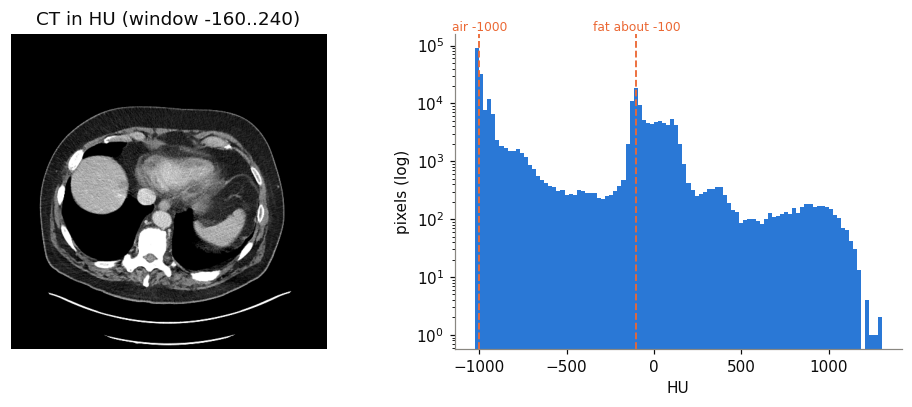

In [18]:
# 図の読み方: 左は HU に直した CT（灰色の濃淡。白いほど HU が大きい）。右は HU のヒストグラム（横軸=HU、縦軸=画素数の対数）。
# 左端の高い山が空気（約 -1000）、-100 付近の山が脂肪。縦線の位置が、物理的に期待する値
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
ax[0].imshow(hu, cmap="gray", vmin=-160, vmax=240)          # 表示の窓 -160〜240 HU は、腹部の軟部組織が見やすい範囲として人が決めた値
ax[0].set_title("CT in HU (window -160..240)"); ax[0].axis("off")
ax[1].hist(hu.ravel(), bins=100, color=BLUE, log=True)       # 100 区間は人が決めた値
for x, label in [(-1000, "air -1000"), (-100, "fat about -100")]:   # 空気は約 -1000 HU、脂肪は約 -100 HU（水は 0 HU と決めてある）
    ax[1].axvline(x, color=ORANGE, lw=1.2, ls="--"); ax[1].text(x, ax[1].get_ylim()[1], label, color=ORANGE, ha="center", va="bottom", fontsize=8)
ax[1].set_xlabel("HU"); ax[1].set_ylabel("pixels (log)")
plt.tight_layout(); plt.show()

In [19]:
# 注意: CT 値に変換した結果に、体内の信号とはかけ離れた値が得られることがある（FOV の外のパディングで、校正の誤りではない）。別の CT（HCC）で確かめる
h = read_dir("ct-hcc")[10]
s = h.pixel_array.astype(float)
hu_h = s * float(h.RescaleSlope) + float(h.RescaleIntercept)
print("画像全体の最小:", hu_h.min(), "HU")                                  # -2048 は、FOV の外のパディングの値（体内の空気は約 -1000）
print("-1100 HU より小さい画素の割合:", round((hu_h < -1100).mean(), 3))      # 画像の何割が、体内とはかけ離れた値か
print("左上の隅 20×20 画素の平均:", hu_h[:20, :20].mean(), "HU")              # かけ離れた値は、隅（FOV の外）にある
inside = hu_h[(hu_h > -1100) & (hu_h < -900)]                               # -1100〜-900 HU = 空気の範囲（人が決めた幅）。撮像範囲の中の空気だけが入る
print("撮像範囲の中の空気の中央値:", np.median(inside), "HU")                  # ここは、ほぼ -1000 になる
print("PixelPaddingValue タグ:", h.get("PixelPaddingValue"), "/ 実際に隅に入っている画素の値:", int(s[0, 0]))

画像全体の最小: -2048.0 HU
-1100 HU より小さい画素の割合: 0.213
左上の隅 20×20 画素の平均: -2048.0 HU
撮像範囲の中の空気の中央値: -974.0 HU
PixelPaddingValue タグ: 63536 / 実際に隅に入っている画素の値: -1024


In [20]:
# PET: 画素の値 → Bq/mL → SUV。SUV(体重) = 放射能濃度(Bq/mL) ÷ ( 投与量(Bq) ÷ 体重(g) )。ただし投与量は、投与から撮像までの減衰を引いた値
from datetime import datetime
pt = sorted(read_dir("pet-psma"), key=lambda d: float(d.ImagePositionPatient[2]))
p0 = pt[0]
print("Units:", p0.Units, "/ 減衰補正:", p0.DecayCorrection)         # BQML = Bq/mL。START = 撮像の開始時刻に合わせて、減衰を補正済み
rp = p0.RadiopharmaceuticalInformationSequence[0]
dose = float(rp.RadionuclideTotalDose)                               # 投与量（Bq）
half = float(rp.RadionuclideHalfLife)                                # 半減期（秒）。F-18 なら約 6586 秒 = 110 分
t_inj = datetime.strptime(rp.RadiopharmaceuticalStartDateTime[:14], "%Y%m%d%H%M%S")   # 投与の日時
t_scan = datetime.strptime(p0.SeriesDate + p0.SeriesTime[:6], "%Y%m%d%H%M%S")         # 撮像の開始時刻（Series の日時）
weight_g = float(p0.PatientWeight) * 1000                            # 体重（kg → g）
dt = (t_scan - t_inj).total_seconds()                                # 投与から撮像開始までの秒数
dose_at_scan = dose * 2 ** (-dt / half)                              # 撮像開始時点で残っている投与量。半減期ごとに半分になる
print(f"投与量 {dose / 1e6:.0f} MBq → {dt / 60:.1f} 分後 {dose_at_scan / 1e6:.1f} MBq / 体重 {weight_g / 1000:.0f} kg")

# 画素の値 → Bq/mL → SUV。校正の式は CT と同じ（stored × RescaleSlope + RescaleIntercept）。スライスごとの値を使う
def suv_slice(d):
    bq_ml = d.pixel_array.astype(float) * float(d.RescaleSlope) + float(d.RescaleIntercept)   # 放射能濃度（Bq/mL）
    return bq_ml * weight_g / dose_at_scan                           # 体重あたりの濃度に直す。SUV = 濃度 ÷ (投与量 ÷ 体重)
suv = np.stack([suv_slice(d) for d in pt])                           # (スライス, 行, 列) の3次元配列
k = np.unravel_index(suv.argmax(), suv.shape)
print(f"SUVmax = {suv.max():.2f}  （スライス {k[0]}、行 {k[1]}、列 {k[2]}）")

Units: BQML / 減衰補正: START
投与量 242 MBq → 51.5 分後 174.8 MBq / 体重 120 kg
SUVmax = 29.52  （スライス 20、行 129、列 85）


In [21]:
# 突き合わせ: 自分で計算した Bq/mL（stored × Slope + Intercept）と、pydicom の関数 apply_modality_lut（同じ校正をライブラリが行う）の結果が一致するか
try:
    from pydicom.pixels import apply_modality_lut                             # pydicom 3 以降
except ImportError:
    from pydicom.pixel_data_handlers.util import apply_modality_lut          # pydicom 2
mine = np.stack([d.pixel_array.astype(float) * float(d.RescaleSlope) + float(d.RescaleIntercept) for d in pt])   # 自分の式
lib = np.stack([apply_modality_lut(d.pixel_array, d) for d in pt])           # ライブラリの校正
print("RescaleSlope の種類:", {float(d.RescaleSlope) for d in pt}, "/ RescaleIntercept の種類:", {float(d.RescaleIntercept) for d in pt})
print("Bq/mL の最大の差（自分 − ライブラリ）:", np.abs(mine - lib).max())          # 0 なら、一致
print("SUV の最大の差（上の suv − ライブラリ経由）:", np.abs(suv - lib * weight_g / dose_at_scan).max())

RescaleSlope の種類: {6.4039} / RescaleIntercept の種類: {0.0}
Bq/mL の最大の差（自分 − ライブラリ）: 0.0
SUV の最大の差（上の suv − ライブラリ経由）: 0.0


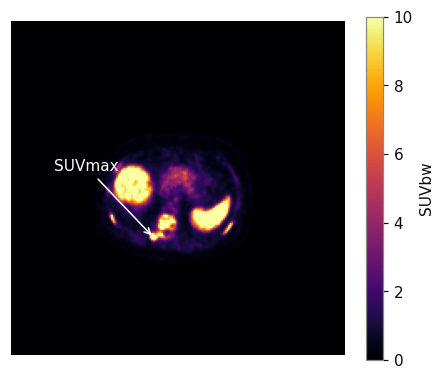

In [22]:
# 図の読み方: SUV のスライス（色が明るいほど SUV が大きい。右の棒が SUV の目盛り）。矢印の先が SUVmax の位置。
# 表示の範囲 0〜10 は、見やすさから人が決めた値（SUV の標準的な窓として使われる 0〜7 より広め）
fig, ax = plt.subplots(figsize=(4.2, 4.2))
im = ax.imshow(suv[k[0]], cmap="inferno", vmin=0, vmax=10)
ax.annotate("SUVmax", xy=(k[2], k[1]), xytext=(k[2] - 60, k[1] - 40), color="white", arrowprops=dict(arrowstyle="->", color="white"))
ax.axis("off"); plt.colorbar(im, ax=ax, shrink=0.8, label="SUVbw"); plt.tight_layout(); plt.show()

In [23]:
# GRAPHY-Next との突き合わせ。GRAPHY-Next で SUV 校正を適用し、画像の上にカーソルを置くと、上のバーに「値（SUV）」と「XY（画素の座標）」が出る。
# 下の4点は、スライス Z 22/40（IPP の z = -471.5 mm）で、2026-10-14 に GRAPHY-Next（v0.4.0）の画面から読み写した値。自分の画面でも、好きな点で試す
zs = np.array([float(d.ImagePositionPatient[2]) for d in pt])       # スライスごとの z（mm）。suv は z の小さい順に並んでいる

def suv_at(z, x, y):
    """GRAPHY-Next の XY（小数）を四捨五入して画素の添え字にし、z に最も近いスライスの SUV を返す"""
    k = int(np.argmin(np.abs(zs - z)))
    return suv[k, int(round(y)), int(round(x))]            # 配列の添え字は (スライス, 行, 列)。XY の X が列、Y が行

seen = [(71.6, 97.3, 9.99), (91.0, 122.7, 17.38), (119.7, 115.3, 16.45), (76.3, 103.3, 9.20)]   # (X, Y, GRAPHY-Next の値)
print(pd.DataFrame([{"X": x, "Y": y, "GRAPHY-Next": g, "this notebook": round(suv_at(-471.5, x, y), 2)} for x, y, g in seen]).to_string(index=False))

    X     Y  GRAPHY-Next  this notebook
 71.6  97.3         9.99           9.99
 91.0 122.7        17.38          17.38
119.7 115.3        16.45          16.45
 76.3 103.3         9.20           9.20


In [24]:
# 撮像時刻のとり方で、SUV はどれくらい変わるか。スライスごとの AcquisitionTime（撮像時刻）を使った場合と比べる
t_acq = datetime.strptime(p0.AcquisitionDate + p0.AcquisitionTime[:6], "%Y%m%d%H%M%S")
dose_alt = dose * 2 ** (-(t_acq - t_inj).total_seconds() / half)
print(f"Series の時刻: {dt / 60:.1f} 分 / Acquisition の時刻: {(t_acq - t_inj).total_seconds() / 60:.1f} 分")
print(f"SUVmax の違い: {suv.max():.2f} → {suv.max() * dose_at_scan / dose_alt:.2f}  （{(dose_at_scan / dose_alt - 1) * 100:+.1f}%）")

Series の時刻: 51.5 分 / Acquisition の時刻: 58.6 分
SUVmax の違い: 29.52 → 30.87  （+4.6%）


In [25]:
# MR: 校正のタグが無い。画素の値は装置・条件ごとに違う「相対値」で、HU や SUV のような物理量ではない
mr = read_dir("mr-lgg")
for d in mr[:6:3]:
    print(d.SeriesDescription[:24].ljust(24), "RescaleSlope" in d, "画素の値", d.pixel_array.min(), "〜", d.pixel_array.max())

Gad Ax T2 Straight       False 画素の値 0 〜 2204
Gad Ax SPGR Straight     False 画素の値 0 〜 399


In [28]:
def suv_wrong(d):
    return d.pixel_array.astype(float) * float(d.RescaleSlope) * weight_g / dose_at_scan # 投与量をそのまま使う
suv2 = np.stack([suv_wrong(d) for d in pt])
print(f"SUVmax = {suv2.max():.2f}")

SUVmax = 29.52


In [29]:
def affine(ds, k_spacing):
    """画素の添え字 (列 j, 行 i, スライス k) を患者座標 (x, y, z) mm に直す 4×4 行列を返す。
    ds=そのスライスの1枚目、k_spacing=スライス間隔(mm)。座標系は LPS（x:右→左, y:前→後ろ, z:足→頭）"""
    iop = np.array(ds.ImageOrientationPatient, dtype=float)
    r, c = iop[:3], iop[3:]                       # r = 列が増える向き（行の方向）、c = 行が増える向き
    n = np.cross(r, c)                            # スライスが重なる向き（法線）。r と c の外積
    ps = [float(v) for v in ds.PixelSpacing]      # PixelSpacing = [行の間隔, 列の間隔]。順番に注意（行の間隔が先）
    M = np.eye(4)
    M[:3, 0] = r * ps[1]                          # 列が1つ進むと、r の向きに ps[1] mm
    M[:3, 1] = c * ps[0]                          # 行が1つ進むと、c の向きに ps[0] mm
    M[:3, 2] = n * k_spacing                      # スライスが1つ進むと、n の向きに k_spacing mm
    M[:3, 3] = np.array(ds.ImagePositionPatient, dtype=float)   # (0,0,0) の画素の位置 = IPP
    return M

def sort_by_position(series):
    """スライスを、法線方向の位置（mm）で並べ替える。InstanceNumber ではなく、IPP を使う"""
    iop = np.array(series[0].ImageOrientationPatient, dtype=float)
    n = np.cross(iop[:3], iop[3:])
    pos = [float(np.dot(n, np.array(d.ImagePositionPatient, dtype=float))) for d in series]
    order = np.argsort(pos)
    return [series[i] for i in order], np.array(pos)[order]

In [30]:
# スライス間隔を、IPP の差から実測して、SliceThickness（厚み）や SpacingBetweenSlices と比べる
# （ct-hcc の 36 枚は、元のシリーズの2回の撮像（AcquisitionNumber 1・2）から、SEG が参照するスライスだけを集めたもの。位置はずれて重なっているので、位置の順に並べると 5 mm 間隔になる）
rows = []
for name in ["ct-psma", "pet-psma", "ct-hcc", "mr-lgg"]:
    series = read_dir(name)
    if name == "mr-lgg":
        series = [d for d in series if d.SeriesDescription == series[0].SeriesDescription]     # 1シリーズだけ
    s, pos = sort_by_position(series)
    rows.append({"series": name, "slices": len(s), "SliceThickness": float(s[0].SliceThickness),
                 "SpacingBetweenSlices": s[0].get("SpacingBetweenSlices", "—"),
                 "measured spacing (mm)": sorted(set(np.round(np.diff(pos), 2).tolist()))})
pd.DataFrame(rows)

,series,slices,SliceThickness,SpacingBetweenSlices,measured spacing (mm)
0,ct-psma,12,3.0,—,[3.0]
1,pet-psma,40,3.0,—,[2.0]
2,ct-hcc,36,5.0,—,[5.0]
3,mr-lgg,3,3.0,3.0,"[6.0, 24.0]"


In [31]:
# 位置の変換を試す。まず、PET と CT をそれぞれ z の順に並べ、CT の真ん中のスライスと同じ高さの PET のスライスを選ぶ
ptS, ptPos = sort_by_position(pt)
ctS, ctPos = sort_by_position(ct)
zc = ctPos[len(ctPos) // 2]                                # CT の真ん中のスライスの z（mm）
ic = int(np.argmin(np.abs(ctPos - zc))); ip = int(np.argmin(np.abs(ptPos - zc)))   # 同じ z に最も近い CT と PET のスライスの添え字
M_pt = affine(ptS[0], k_spacing=float(np.diff(ptPos).mean()))     # 1枚目の IPP を基準にした行列。k はその1枚目からの枚数
M_ct = affine(ctS[0], k_spacing=float(np.diff(ctPos).mean()))
p = M_pt @ np.array([100, 100, ip, 1.0])                   # 同次座標（最後の 1 は、平行移動を掛け算で表すための決まり）
print(f"PET 画素 (列100, 行100, スライス{ip}) →", np.round(p[:3], 1), "mm")
back = np.linalg.inv(M_pt) @ p                           # 逆行列で、患者座標 → 画素に戻す
print("戻した添え字:", np.round(back[:3], 6))              # (100, 100, ip) に戻れば、変換が正しい
q = np.linalg.inv(M_ct) @ p                              # 同じ患者座標を、CT の画素の添え字にする
print("同じ位置の CT 画素 (列, 行, スライス) =", np.round(q[:3], 1))   # 列・行は 0〜511、スライスは 0〜11 の中に入る

PET 画素 (列100, 行100, スライス20) → [   0.9 -197.9 -473.5] mm
戻した添え字: [100. 100.  20.]
同じ位置の CT 画素 (列, 行, スライス) = [256.4 257.2   6. ]


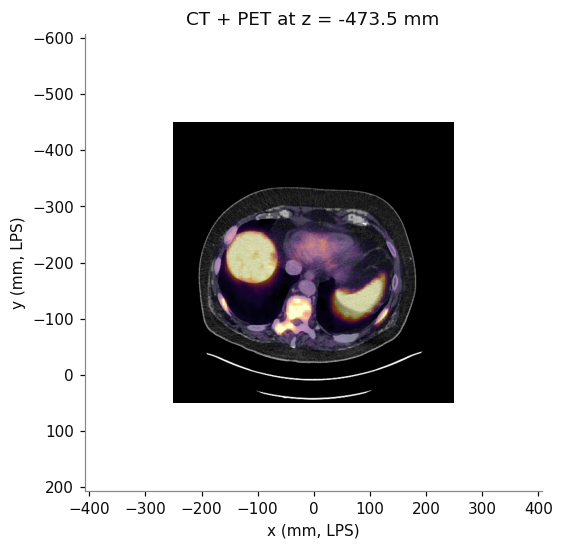

In [32]:
# 図の読み方: 横軸・縦軸は患者座標 x・y（mm）。灰色が CT、色（紫〜黄）が PET の SUV を重ねたもの（SUV 0.5 未満は透明）。
# 画像の大きさが違っても、座標（mm）が共通なので、位置が合う（体の輪郭が重なる）
def extent(M, shape):
    """imshow の extent（左・右・下・上の mm）を、affine から作る。画素の中心ではなく、画素の端を基準にするので 0.5 画素ずらす"""
    x0, y0 = (M @ np.array([-0.5, -0.5, 0, 1]))[:2]; x1, y1 = (M @ np.array([shape[1] - 0.5, shape[0] - 0.5, 0, 1]))[:2]
    return [x0, x1, y1, y0]
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ct_hu = ctS[ic].pixel_array.astype(float) * float(ctS[ic].RescaleSlope) + float(ctS[ic].RescaleIntercept)   # CT を HU に直す（第5節と同じ）
ax.imshow(ct_hu, cmap="gray", vmin=-160, vmax=240, extent=extent(M_ct, ct_hu.shape))
ax.imshow(np.ma.masked_less(suv[ip], 0.5), cmap="inferno", vmin=0, vmax=10, alpha=0.5, extent=extent(M_pt, suv[ip].shape))   # SUV 0.5 未満は透明にして、CT を見せる（0.5 は人が決めた値）   # suv は z の小さい順に並べてあり、ptS と同じ順
ax.set_xlabel("x (mm, LPS)"); ax.set_ylabel("y (mm, LPS)"); ax.set_title(f"CT + PET at z = {zc:.1f} mm")
plt.tight_layout(); plt.show()

In [33]:
series = read_dir("ct-hcc")
series.sort(key=lambda d: int(d.InstanceNumber))               # InstanceNumber の順に並べる
z = [float(d.ImagePositionPatient[2]) for d in series]
print("z の間隔の平均:", np.diff(z).mean(), "mm")
print(np.diff(z))

z の間隔の平均: -4.714285714285714 mm
[ -5. -15.  -5. -15. -15.  -5.  -5.  -5. -10. -20.  -5.  -5.  -5.  -5.
 130.  -5. -15.  -5. -15.  -5. -10.  -5. -25. -10.  -5.  -5. -30.  -5.
  -5.  -5.  -5.  -5.  -5.  -5.  -5.]


In [34]:
series = read_dir("ct-psma"); s_, pos_ = sort_by_position(series)
ps = [float(v) for v in s_[0].PixelSpacing]
print(s_[0].Columns * ps[1], s_[0].Rows * ps[0], pos_.max() - pos_.min())

500.0 500.0 33.0


In [35]:
# 座標系の確認: 同じ FrameOfReferenceUID なら、CT と PET は同じ患者座標の空間にある（違うと、mm が同じでも重ならない）
print("同じ座標系か:", ptS[0].FrameOfReferenceUID == ctS[0].FrameOfReferenceUID)

def resample(M_target, shape, vol, M_src, order):
    """出力の格子（shape=(スライス, 行, 列)、位置は M_target）の各点について、vol（位置は M_src）の値を読んで返す。
    order=0: 最近傍（いちばん近い画素の値）、order=1: 線形（まわりの画素を距離で重みづけして平均）。vol の外は NaN（0 で埋めない）"""
    K, I, J = np.indices(shape)                                                  # 出力の画素の添え字（スライス k、行 i、列 j）
    idx = np.stack([J, I, K, np.ones_like(J)]).reshape(4, -1).astype(float)      # (列, 行, スライス, 1)。affine の入力の並びに合わせる
    mm = M_target @ idx                                                          # 出力の画素 → 患者座標（mm）
    src = np.linalg.inv(M_src) @ mm                                              # 患者座標 → vol の添え字（小数）
    out = map_coordinates(vol, [src[2], src[1], src[0]], order=order, mode="constant", cval=np.nan)   # map_coordinates は (スライス, 行, 列) の順で渡す
    return out.reshape(shape)

ct_vol = np.stack([d.pixel_array.astype(float) * float(d.RescaleSlope) + float(d.RescaleIntercept) for d in ctS])   # CT を HU に直したボリューム (12, 512, 512)
suv_nn = resample(M_ct, ct_vol.shape, suv, M_pt, order=0)      # PET の SUV を CT の格子へ（最近傍）
suv_li = resample(M_ct, ct_vol.shape, suv, M_pt, order=1)      # 同じ（線形）
print("CT の格子:", ct_vol.shape, "/ PET の格子:", suv.shape, "/ 範囲外（NaN）の画素:", int(np.isnan(suv_nn).sum()), int(np.isnan(suv_li).sum()))

同じ座標系か: True
CT の格子: (12, 512, 512) / PET の格子: (40, 200, 200) / 範囲外（NaN）の画素: 0 0


In [36]:
# 正例: PET 自身の格子へ戻すと、線形でも元と一致するはず（格子の点では、補間は元の値を返す）
back = resample(M_pt, suv.shape, suv, M_pt, order=1)
print("PET → PET の最大の差:", np.abs(back - suv).max())

# 最近傍と線形で、SUV はどう変わるか。PET の格子での SUVmax と、CT の格子での SUVmax を比べる
print(f"SUVmax  PET の格子: {suv.max():.2f} / CT の格子（最近傍）: {np.nanmax(suv_nn):.2f} / CT の格子（線形）: {np.nanmax(suv_li):.2f}  （線形は {np.nanmax(suv_li) / suv.max() * 100:.1f}%）")
body = ct_vol > -300                                           # CT の「体」の画素。-300 HU は、空気（-1000）と軟部組織（0 付近）の間に人が決めた値
print(f"体の中の SUV の平均  最近傍: {np.nanmean(suv_nn[body]):.3f} / 線形: {np.nanmean(suv_li[body]):.3f}")

# 位置が合っているかの検査: CT から作った「体」と、PET から作った「体」（SUV > 0.5）の重なり（Dice: 1 = 完全に一致、0 = 重ならない）。独立な2つの装置の画像で測る
def body_dice(pet_on_ct):
    ok = ~np.isnan(pet_on_ct)                                  # 範囲外は含めない
    a = body & ok; b = (np.nan_to_num(pet_on_ct) > 0.5) & ok   # 0.5 は、第6節の重ね図と同じ（人が決めた値）
    return 2 * (a & b).sum() / (a.sum() + b.sum())
print(f"体の一致（Dice）  最近傍: {body_dice(suv_nn):.3f} / 線形: {body_dice(suv_li):.3f}")

PET → PET の最大の差: 4.360956040727615e-13
SUVmax  PET の格子: 29.52 / CT の格子（最近傍）: 29.52 / CT の格子（線形）: 28.89  （線形は 97.9%）
体の中の SUV の平均  最近傍: 2.590 / 線形: 2.617
体の一致（Dice）  最近傍: 0.722 / 線形: 0.723


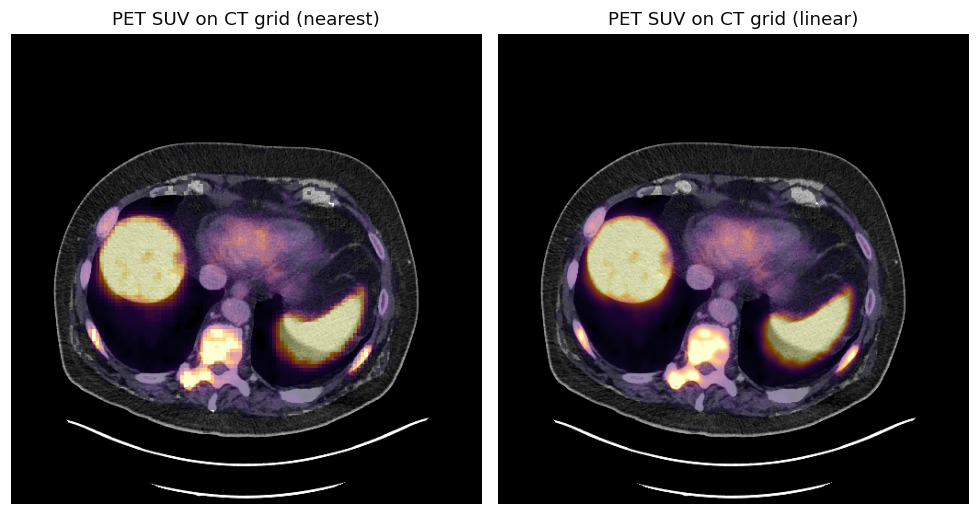

In [37]:
# 図の読み方: 横軸・縦軸は CT の画素（列・行）。灰色が CT、色（紫〜黄）が、CT の格子に載せた PET の SUV（SUV 0.5 未満は透明）。
# 左は最近傍（PET の1画素＝約 4 mm の四角がそのまま見える）、右は線形（なめらかにつながる）。どちらも同じ位置（体の輪郭に合う）
kz = ct_vol.shape[0] // 2                                      # 真ん中のスライス
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, v, title in [(axes[0], suv_nn, "nearest"), (axes[1], suv_li, "linear")]:
    ax.imshow(ct_vol[kz], cmap="gray", vmin=-160, vmax=240)
    ax.imshow(np.ma.masked_less(v[kz], 0.5), cmap="inferno", vmin=0, vmax=10, alpha=0.5)
    ax.set_title(f"PET SUV on CT grid ({title})"); ax.axis("off")
plt.tight_layout(); plt.show()

In [38]:
K, I, J = np.indices(ct_vol.shape)
wrong = map_coordinates(suv, [K * suv.shape[0] / ct_vol.shape[0],
                              I * suv.shape[1] / ct_vol.shape[1],
                              J * suv.shape[2] / ct_vol.shape[2]], order=1, mode="constant", cval=np.nan)   # 添え字の比で対応づける
print(f"体の一致（Dice）: {body_dice(wrong):.3f}")

体の一致（Dice）: 0.373


In [39]:
fixed = resample(M_ct, ct_vol.shape, suv, M_pt, order=1)
print(f"体の一致（Dice）: {body_dice(fixed):.3f}")

体の一致（Dice）: 0.723
